# FFM-OSLO v2.6 — 四库从零训练（CARLab + HUTUBS + SONICOM + SYMARE61）

**774 人。** 在 v2.3 的三库 713 人基础上加入 SYMARE61,从零重训 100 epoch。

Craig 已确认:新采集的 CARLab 与旧的 61 人 SYMARE **是完全不同的人**。
因此不做任何跨库双胞胎防护,SYMARE 就是第四个独立数据库。

数据:`{DRIVE}/ELEC5020/SYMARE.zip` → `npy_left` / `npy_right`,
`SYM_HA01…SYM_HA61`,形状 **(129, 3072)**,已重采样到 44.1 kHz,
和其它三库一样 `[:93]` 截到 93 bin。

---

## 这次重训真正买到的东西

不只是多 61 个人(+8.6%)。**更重要的是它把 `symare61_to_carlab_RESOLVED.csv` 从
下游流程里彻底移除了。**

`landmark2z` 此前的做法是:SYMARE 的 landmark → 经映射表找到"对应"的 CARLab 受试者
→ 用那个人的 latent。既然两批人不重合,那张映射表配的就是错的对,
**之前那批 R² / dCor 数字量的不是"几何 → 这个人的 latent"**,必须重跑。

重训之后,SYMARE 受试者**有自己的 latent**,不需要任何映射。这是干净得多的实验:

| | 旧(v2.3 + 映射) | 新(v2.6) |
|---|---|---|
| 配对方式 | 频谱最近邻,可能配错人 | **同一个人,无需配对** |
| 可用受试者 | 52(A1+A2 高置信) | **61(全部)** |
| AE 见过其 HRTF | 否(SYMARE 不在训练里) | 是 |

## 划分

SYMARE 用 `(0.60, 0.15, 0.25)`,和 HUTUBS 一样把 test 比例设高——理由相同:
**它是带几何的库,test 集要留给下游 geometry→latent 工作。**
61 人 → 约 37 train / 9 val / 15 test。

`split_v21.json` **沿用不改名**。`build_split` 是增量的:CARLab / HUTUBS / SONICOM
的划分逐字不变,只追加一个 `SYMARE` 键。

## 报数纪律

- checkpoint 叫 `FFM26_*`,**不覆盖 `FFM23_*`**。
- v2.6 的任何数字都**不能替换** v2.3 的 1.4867 / 1.2909。四库模型 + FiLM 跨库
  中心化多了一行 = 不同的模型。要么整篇用 v2.3,要么整篇用 v2.6,不要混。
- CARLab 的 test 名单和 v2.3 完全相同,所以两个模型在同一批人上的比较是有意义的
  ——但那是"三库 vs 四库"的对照,不是同一个数字的更新。

In [ ]:
# ==========================================================================
# Cell 0 — 数据准备（四库）
#
# 两种 zip 布局混用，靠 dirs 里的文件夹名区分，代码是同一套（递归查找）：
#   CARLab       : ELEC5021/CARLab/*_left.zip + *_right.zip -> CARLab_44k1_left/right
#   其余三个库   : ELEC5020/<库>.zip（单个）                -> npy_left / npy_right
#
# ★ 每个库解压到【各自的】extract_to。HUTUBS / SONICOM / SYMARE 解出来的目录
#   都叫 npy_left，共用一个解压根目录会让 find_dir 认错库。
#
# id 决定 FiLM 的行号，一旦训练过就不要重排。
# ==========================================================================
import os, zipfile
from google.colab import drive

drive.mount('/content/drive')

DRIVE = '/content/drive/MyDrive'
BASE = '/content/dataset'

DATASETS_SPEC = [
    dict(id=0, tag='CARLab',
         zips=[f'{DRIVE}/ELEC5021/CARLab/CARLab_44k1_left.zip',
               f'{DRIVE}/ELEC5021/CARLab/CARLab_44k1_right.zip'],
         extract_to=f'{BASE}/carlab',
         dirs=('CARLab_44k1_left', 'CARLab_44k1_right'),
         split=(0.80, 0.10, 0.10)),
    dict(id=1, tag='HUTUBS',
         zips=[f'{DRIVE}/ELEC5020/HUTUBS.zip'],
         extract_to=f'{BASE}/hutubs',
         dirs=('npy_left', 'npy_right'),
         split=(0.60, 0.15, 0.25)),          # 自带 58 个 mesh -> 多留 test
    dict(id=2, tag='SONICOM',
         zips=[f'{DRIVE}/ELEC5020/SONICOM.zip'],
         extract_to=f'{BASE}/sonicom',
         dirs=('npy_left', 'npy_right'),
         split=(0.75, 0.10, 0.15)),
    dict(id=3, tag='SYMARE',                  # ★ 新增第四库
         zips=[f'{DRIVE}/ELEC5020/SYMARE.zip'],
         extract_to=f'{BASE}/symare',
         dirs=('npy_left', 'npy_right'),
         split=(0.60, 0.15, 0.25)),          # 带几何 -> 和 HUTUBS 同理多留 test
]

KNOWN_SUFFIX = ['_left_full.npy', '_left.npy', '_Left.npy', '_L.npy', '-left.npy']
L2R = [('_left_full', '_right_full'), ('_left', '_right'), ('_Left', '_Right'),
       ('-left', '-right'), ('_L.', '_R.')]


def find_dir(root, target):
    """递归找名为 target 的文件夹，跳过 __MACOSX，选 .npy 最多的那个"""
    cands = []
    for dp, _, fns in os.walk(root):
        if '__MACOSX' in dp:
            continue
        if os.path.basename(dp) == target:
            cands.append((sum(f.endswith('.npy') for f in fns), dp))
    cands.sort(reverse=True)
    return cands[0][1] if cands else None


def detect_suffix(d):
    """识别 '<受试者编号><后缀>' 里的后缀。先试常见的，再退回最长公共后缀。"""
    names = sorted(f for f in os.listdir(d) if f.endswith('.npy'))
    assert names, f'{d} 里没有 .npy'
    for s in KNOWN_SUFFIX:
        if all(n.endswith(s) for n in names):
            return s, names
    s = names[0]
    for n in names[1:]:
        i = 0
        while i < min(len(s), len(n)) and s[-1 - i] == n[-1 - i]:
            i += 1
        s = s[len(s) - i:]
    return s, names


def right_of(sl):
    for a, b in L2R:
        if a in sl:
            return sl.replace(a, b)
    return None


DATASETS = []
for spec in DATASETS_SPEC:
    tag, out = spec['tag'], spec['extract_to']
    os.makedirs(out, exist_ok=True)
    ok = True
    for zp in spec['zips']:
        if os.path.exists(zp):
            with zipfile.ZipFile(zp) as z:
                z.extractall(out)
        else:
            print(f'[{tag}] ★ 找不到 {zp}'); ok = False
    if not ok:
        continue

    dl, dr = spec['dirs']
    ld, rd = find_dir(out, dl), find_dir(out, dr)
    if ld is None or rd is None:
        print(f'[{tag}] ★ 解压后没找到 {dl} / {dr}，检查 zip 结构')
        continue

    sl, ln = detect_suffix(ld)
    sr = right_of(sl)
    rn = sorted(f for f in os.listdir(rd) if f.endswith('.npy'))
    if sr is None or not all(n.endswith(sr) for n in rn):
        sr, rn = detect_suffix(rd)

    ids_l = {n[:-len(sl)] for n in ln}
    ids_r = {n[:-len(sr)] for n in rn}
    assert all(ids_l) and len(ids_l) == len(ln), \
        f'{tag}: 后缀 {sl!r} 识别有问题，切出来的编号有空或重复'
    common = sorted(ids_l & ids_r)

    print(f"[{tag}] id={spec['id']}  left {len(ln)} / right {len(rn)}  "
          f'后缀 {sl!r} / {sr!r}  双耳齐全 {len(common)} 人')
    print(f'         {ld}')
    print(f'         编号示例: {common[:4]} ... {common[-2:]}')
    if ids_l ^ ids_r:
        print(f'         ⚠️ {len(ids_l ^ ids_r)} 人只有一只耳（自动跳过）: '
              f'{sorted(ids_l ^ ids_r)[:6]}')

    DATASETS.append(dict(id=spec['id'], tag=tag, left=ld, right=rd,
                         suffix=(sl, sr), split=spec['split']))

DATASETS = sorted(DATASETS, key=lambda d: d['id'])
assert DATASETS, '一个库都没加载成功'
assert [d['id'] for d in DATASETS] == list(range(len(DATASETS))), (
    f"id 必须从 0 连续，当前是 {[d['id'] for d in DATASETS]} —— "
    '少一个库就把 DATASETS_SPEC 里后面的 id 顺次改小')

# mirror idx：三个历史位置按序找，都没有就在 Cell 3 现场生成（已核对逐位相同）
MIRROR_SRC = next((p for p in (
    f'{DRIVE}/ELEC5021/analysis/healpix_mirror_idx.npy',
    f'{DRIVE}/HRTF_Checkpoints/healpix_mirror_idx.npy',
    f'{DRIVE}/healpix_mirror_idx.npy') if os.path.exists(p)),
    f'{DRIVE}/ELEC5021/analysis/healpix_mirror_idx.npy')
print(f"\n共 {len(DATASETS)} 个库 | mirror idx: "
      f"{'找到' if os.path.exists(MIRROR_SRC) else '★缺失，Cell 3 会现场生成'}")

no_meta = [d['tag'] for d in DATASETS
           if not os.path.exists(os.path.join(d['left'], 'meta.json'))]
if no_meta:
    print(f'\n⚠️ 这些库没有 meta.json，Cell 1 只能核对形状不能核对采样率: {no_meta}')
    print('   四个库必须都是 44.1 kHz / 256 点 / 129 bin。48 kHz 的 df=187.5 Hz，')
    print('   44.1 kHz 的 df=172.27 Hz —— 同一个 bin 索引差 8%，在 notch 带错位')
    print('   接近 1 kHz。混着训不会报错，只会悄悄变差。')


Mounted at /content/drive
[CARLab] id=0  left 218 / right 218  后缀 '_left_full.npy' / '_right_full.npy'  双耳齐全 218 人
         /content/dataset/carlab/CARLab_44k1_left
         编号示例: ['CL001', 'CL002', 'CL003', 'CL004'] ... ['CL217', 'CL218']
[HUTUBS] id=1  left 96 / right 96  后缀 '_left_full.npy' / '_right_full.npy'  双耳齐全 96 人
         /content/dataset/hutubs/HUTUBS/npy_left
         编号示例: ['HU_pp1', 'HU_pp10', 'HU_pp11', 'HU_pp12'] ... ['HU_pp95', 'HU_pp96']
[SONICOM] id=2  left 399 / right 399  后缀 '_left_full.npy' / '_right_full.npy'  双耳齐全 399 人
         /content/dataset/sonicom/SONICOM/npy_left
         编号示例: ['SON_P0001', 'SON_P0002', 'SON_P0003', 'SON_P0004'] ... ['SON_P0404', 'SON_P0405']
[SYMARE] id=3  left 61 / right 61  后缀 '_left_full.npy' / '_right_full.npy'  双耳齐全 61 人
         /content/dataset/symare/SYMARE/npy_left
         编号示例: ['SYM_HA01', 'SYM_HA02', 'SYM_HA03', 'SYM_HA04'] ... ['SYM_HA60', 'SYM_HA61']

共 4 个库 | mirror idx: 找到

⚠️ 这些库没有 meta.json，Cell 1 只能核对形状不能核对采样率: ['HU

In [ ]:
!pip install healpy -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 161.1 MB/s eta 0:00:00


In [ ]:
# ==========================================================================
# Cell 1 — 采样率 / 频率轴一致性（四库都要过）
#
# 同一个 bin 索引在不同采样率下是不同的物理频率:
#   48   kHz / 256 : df = 187.50 Hz, bin 64 = 12000 Hz
#   44.1 kHz / 256 : df = 172.27 Hz, bin 64 = 11025 Hz
# 错了会把 notch 移位近 1 kHz,而且不报错。
# ==========================================================================
import numpy as np, json, os

EXPECT_FS, EXPECT_NFFT, EXPECT_BINS, EXPECT_NPIX = 44100, 256, 129, 3072
DF = EXPECT_FS / EXPECT_NFFT
FREQ_CAP_HZ = 16000
N_BINS = int(np.floor(FREQ_CAP_HZ / DF)) + 1          # -> 93
print(f'df = {DF:.4f} Hz | N_BINS = {N_BINS} (DC–{(N_BINS-1)*DF/1000:.2f} kHz)')
assert N_BINS == 93, f'N_BINS={N_BINS},不是 93 —— FREQ_CAP_HZ 被改过'

ok = True
for d in DATASETS:
    f = sorted(x for x in os.listdir(d['left']) if x.endswith('.npy'))[0]
    a = np.load(os.path.join(d['left'], f))
    good = a.shape == (EXPECT_BINS, EXPECT_NPIX)
    mj = os.path.join(d['left'], 'meta.json')
    fs = json.load(open(mj)).get('sample_rate') if os.path.exists(mj) else None
    print(f"{d['tag']:<9} {a.shape}  {'OK' if good else '★形状不对'}"
          f"  meta fs={fs if fs else '(无 meta.json)'}"
          + ('  ★fs 不是 44100' if fs not in (None, EXPECT_FS) else ''))
    ok &= good and fs in (None, EXPECT_FS)
assert ok, 'SYMARE 没有 meta.json 是正常的（老管线导出）,但形状必须对得上'
print('\n四库频率轴一致 ✓')

df = 172.2656 Hz | N_BINS = 93 (DC–15.85 kHz)
CARLab    (129, 3072)  OK  meta fs=44100
HUTUBS    (129, 3072)  OK  meta fs=(无 meta.json)
SONICOM   (129, 3072)  OK  meta fs=(无 meta.json)
SYMARE    (129, 3072)  OK  meta fs=(无 meta.json)

四库频率轴一致 ✓


In [ ]:
# ==========================================================================
# Cell 2 - 模型定义（GELU + FiLM）
#
# 与 FFM_2_3_MultiDB.ipynb 逐字相同，构建时复制进来，运行时不依赖那个文件。
# 架构不要改：FFM26_*.pth 的权重形状由这里决定。
# ==========================================================================
import numpy as np
import torch
import torch.nn as nn
import healpy as hp


# ---------------------------------------------- spherical convolution
class OSLOConv(nn.Module):
    """Anisotropic convolution on HEALPix: each pixel plus its 8 neighbours, 9 independent weights."""
    def __init__(self, in_channels, out_channels, nside=16):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        neighbors = hp.get_all_neighbours(nside, np.arange(self.npix))
        rf = np.concatenate([neighbors, np.arange(self.npix)[np.newaxis, :]], axis=0)
        rf[rf == -1] = self.npix
        self.register_buffer('neighborhood', torch.tensor(rf, dtype=torch.int64))
        self.weight = nn.Parameter(torch.empty(out_channels, in_channels, 9))
        self.bias = nn.Parameter(torch.empty(out_channels))
        nn.init.kaiming_uniform_(self.weight, a=np.sqrt(5))
        nn.init.zeros_(self.bias)

    def forward(self, x):
        B, C, _ = x.shape
        pad = torch.zeros(B, C, 1, device=x.device, dtype=x.dtype)
        g = torch.cat([x, pad], dim=2)[:, :, self.neighborhood]
        return torch.einsum('bcqn,ocq->bon', g, self.weight) + self.bias.view(1, -1, 1)


class OSLOResBlock(nn.Module):
    """Frequency-isolated residual block, operating on (B*F, C, N).
    * v2: ReLU -> GELU. HRTF log-magnitude is bipolar (negative means attenuation), so
      ReLU truncates the negative half; GELU is smooth, keeps negatives, and matches the fc layers."""
    def __init__(self, in_channels, out_channels, nside=16, num_groups=8):
        super().__init__()
        self.shortcut = (nn.Conv1d(in_channels, out_channels, 1)
                         if in_channels != out_channels else nn.Identity())
        self.conv1 = OSLOConv(in_channels, out_channels, nside)
        self.gn1 = nn.GroupNorm(num_groups, out_channels)
        self.conv2 = OSLOConv(out_channels, out_channels, nside)
        self.gn2 = nn.GroupNorm(num_groups, out_channels)
        self.act = nn.GELU()

    def forward(self, x):
        res = self.shortcut(x)
        out = self.act(self.gn1(self.conv1(x)))
        out = self.gn2(self.conv2(out))
        return self.act(out + res)


# ---------------------------------------------- per-dataset FiLM
class DatasetFiLM(nn.Module):
    """Learn one PER-FREQUENCY scale/shift curve for each dataset.

    ** Constraint 1: frequency only, NEVER direction.
      A per-frequency affine map is one EQ curve (93 dof per dataset). All it can absorb is
      "colouration common to the whole dataset and independent of direction" — loudspeaker and
      microphone response, equalisation convention, overall level. By construction it CANNOT
      express a direction-dependent difference, so population anatomy (ear-size distributions
      differ across databases) must still live in z. Contrast: subtracting a per-database mean
      over (frequency x direction) is 3072x93 dof, enough to remove the real population structure
      as well — exactly the wrong direction Craig pointed at. A factor of 3072 in expressive power.

    ** Constraint 2: centre across datasets.
      Without centring, log_gamma/beta learn a global EQ that cancels against the network's own
      output gain — a redundant degree of freedom. After the cross-database mean is removed FiLM
      expresses only RELATIVE differences; the absolute part stays in the network. Exactly the identity when num_datasets=1.
    """
    def __init__(self, num_datasets, num_bins):
        super().__init__()
        self.num_datasets = num_datasets
        self.log_gamma = nn.Parameter(torch.zeros(num_datasets, num_bins))
        self.beta = nn.Parameter(torch.zeros(num_datasets, num_bins))

    def params(self, dataset_id):
        lg = self.log_gamma - self.log_gamma.mean(0, keepdim=True)
        bt = self.beta - self.beta.mean(0, keepdim=True)
        return torch.exp(lg[dataset_id]).unsqueeze(-1), bt[dataset_id].unsqueeze(-1)

    def forward(self, x, dataset_id):
        g, b = self.params(dataset_id)
        return x * g + b

    def inverse(self, x, dataset_id):
        g, b = self.params(dataset_id)
        return (x - b) / g


# ---------------------------------------------- encoder / decoder

class Isolated_OSLO_Encoder(nn.Module):
    """Encode each frequency bin independently -> latent (B, F, latent_dim)"""
    def __init__(self, nside=16, latent_dim_per_freq=64):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        self.latent_dim = latent_dim_per_freq
        self.enc1 = OSLOResBlock(1, 16, nside)
        self.enc2 = OSLOResBlock(16, 32, nside)
        self.fc_encode = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * self.npix, 512), nn.GELU(),
            nn.Linear(512, self.latent_dim))

    def forward(self, x):
        B, F, N = x.shape
        z = self.fc_encode(self.enc2(self.enc1(x.reshape(B * F, 1, N))))
        return z.reshape(B, F, self.latent_dim)


class Conditioned_OSLO_Decoder(nn.Module):
    """FFM frequency-conditioned decoder + per-dataset FiLM on the output"""
    def __init__(self, nside=16, latent_dim_per_freq=64, freq_embed_dim=32,
                 num_datasets=1, num_bins=93):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        self.latent_dim = latent_dim_per_freq
        self.freq_embed_dim = freq_embed_dim
        self.ffm_B = nn.Parameter(torch.randn(freq_embed_dim // 2))
        self.fc_decode = nn.Sequential(
            nn.Linear(self.latent_dim + freq_embed_dim, 512), nn.GELU(),
            nn.Linear(512, 32 * self.npix))
        self.dec1 = OSLOResBlock(32, 16, nside)
        self.dec_final = OSLOConv(16, 1, nside)
        self.film = DatasetFiLM(num_datasets, num_bins)

    def get_freq_embedding(self, num_freqs, device):
        f = torch.arange(num_freqs, device=device).float() / (num_freqs - 1)
        proj = 2 * np.pi * f.unsqueeze(1) * self.ffm_B.unsqueeze(0)
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=1)

    def forward(self, z, dataset_id=None):
        B, F, _ = z.shape
        fe = self.get_freq_embedding(F, z.device).unsqueeze(0).expand(B, -1, -1)
        h = torch.cat([z, fe], dim=-1).reshape(B * F, -1)
        h = self.fc_decode(h).reshape(B * F, 32, self.npix)
        out = self.dec_final(self.dec1(h)).reshape(B, F, self.npix)
        if dataset_id is not None:
            out = self.film(out, dataset_id)
        return out


class FFM_OSLO_Autoencoder(nn.Module):
    """One SHARED-parameter inverse FiLM at the encoder input — zero extra parameters.

    With FiLM on the decoder output only, the colouration stays in x, the encoder takes it in, and it
    lands in z — but z is exactly what the downstream geometry->latent stage needs. Output-side FiLM
    only makes the reconstruction loss line up; it does not clean z.

    Here     x_norm = (x - beta)/gamma        <- remove colouration
             z      = encoder(x_norm)
             out    = gamma * decoder(z) + beta   <- back to the original space, loss still on raw

    The SAME FiLM parameters are used. Together with centring this also kills the trivial degenerate
    direction "scale gamma up, scale the network down". Set tie_encoder_film=False to disable.
    """
    def __init__(self, nside=16, latent_dim_per_freq=64, freq_embed_dim=32,
                 num_datasets=1, num_bins=93, tie_encoder_film=True):
        super().__init__()
        self.encoder = Isolated_OSLO_Encoder(nside, latent_dim_per_freq)
        self.decoder = Conditioned_OSLO_Decoder(nside, latent_dim_per_freq,
                                                freq_embed_dim, num_datasets, num_bins)
        self.tie_encoder_film = tie_encoder_film

    def forward(self, x, dataset_id=None):
        if dataset_id is not None and self.tie_encoder_film:
            x = self.decoder.film.inverse(x, dataset_id)
        z = self.encoder(x)
        return self.decoder(z, dataset_id), z


print('model defined (FFM + FiLM)')

model defined (FFM + FiLM)


In [ ]:
# ==========================================================================
# Cell 3 — 配置 · 划分 · 损失 · 模型
# ==========================================================================
import random, hashlib, time
import torch, torch.nn as nn, torch.optim as optim, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset, WeightedRandomSampler
import healpy as hp

config = {
    'model_type': 'FFM-OSLO-v2.6-QuadDB1',
    'nside': 16, 'latent_dim': 64, 'freq_embed_dim': 32,
    'sample_rate': EXPECT_FS, 'num_bins_raw': EXPECT_BINS, 'freq_cap_hz': FREQ_CAP_HZ,
    'flatten_bins': 0, 'band_lo_hz': 0,
    'num_datasets': len(DATASETS), 'tie_encoder_film': True,
    'lr': 1e-4, 'batch_size': 8, 'weight_decay': 1e-4,
    'w_mse': 1.0, 'w_spectral': 0.1, 'amp': True,
    'save_after': 0, 'save_every': 1, 'save_optimizer': False,
    'resume_lr_mult': 0.3,
    'save_dir': '/content/drive/MyDrive/HRTF_Checkpoints',
}
config['num_bins'] = N_BINS
config['band_hi_hz'] = int(round((N_BINS - 1) * DF))
FLAT = config['flatten_bins']

# ★ 和 v2.3 同一套：每一段 resume 都跑一个自己的 cosine 周期
resume            = False   # ★ Colab 掉线之后改 True,从 FFM26_latest.pth 接着跑
fresh_epochs      = 100     # 从零训多少轮
additional_epochs = 30      # 每次 resume 再补多少轮
INIT_FILM_FROM_MEANS = True # β 从实测每库平均谱初始化（SYMARE 比 CARLab 低约 5.2 dB）

os.makedirs(config['save_dir'], exist_ok=True)
latest_path = os.path.join(config['save_dir'], 'FFM26_latest.pth')
best_path   = os.path.join(config['save_dir'], 'FFM26_best.pth')
split_path  = os.path.join(config['save_dir'], 'split_v21.json')   # ★ 沿用,不要改名

seed = 4
torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
      '| AMP bf16:', config['amp'])

# ------------------------------ 镜像置换 ------------------------------
if os.path.exists(MIRROR_SRC):
    MIRROR = np.load(MIRROR_SRC)
else:
    th, ph = hp.pix2ang(config['nside'], np.arange(hp.nside2npix(config['nside'])))
    MIRROR = hp.ang2pix(config['nside'], th, (-ph) % (2 * np.pi))
assert len(np.unique(MIRROR)) == len(MIRROR), '镜像不是双射'
assert np.array_equal(MIRROR[MIRROR], np.arange(len(MIRROR))), '镜像不是对合'
print('镜像置换 OK (精确双射且对合)')


class MonauralHRTFDataset(Dataset):
    """每个样本 = 一只耳朵。右耳沿中矢面镜像,使全部样本进入左耳坐标系。"""
    def __init__(self, d, subject_ids_, mirror):
        self.items, self.mirror, self.dataset_id = [], mirror, d['id']
        sl, sr = d['suffix']
        for sid in sorted(subject_ids_):
            for side, sfx, root in (('left', sl, d['left']), ('right', sr, d['right'])):
                p = os.path.join(root, f'{sid}{sfx}')
                if os.path.exists(p): self.items.append((sid, side, p))
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        sid, side, path = self.items[i]
        x = np.load(path).astype(np.float32)[:N_BINS]
        if FLAT: x[:FLAT] = x[FLAT]
        if side == 'right': x = x[:, self.mirror]
        return torch.from_numpy(x), torch.tensor(self.dataset_id), f'{sid}_{side}'

def subject_ids(d):
    sfx = d['suffix'][0]
    return sorted({f[:-len(sfx)] for f in os.listdir(d['left']) if f.endswith(sfx)})


# --------------------- 划分：按受试者,增量,冻结到磁盘 ---------------------
def build_split(datasets, seed, path):
    sp = json.load(open(path)) if os.path.exists(path) else {}
    changed = False
    for d in datasets:
        ids = subject_ids(d)
        h = hashlib.md5(','.join(ids).encode()).hexdigest()[:12]
        if d['tag'] in sp:
            if sp[d['tag']]['hash'] != h:
                raise RuntimeError(
                    f"{d['tag']} 的受试者名单变了（存档 {sp[d['tag']]['hash']} vs 现在 {h}）。"
                    '重新划分会污染 test 集 —— 先确认这是不是预期的。')
            print(f"  沿用 {d['tag']} 的已冻结划分"); continue
        rng = np.random.default_rng(seed + d['id'])
        perm = list(ids); rng.shuffle(perm)
        ftr, fva, _ = d['split']
        n = len(perm); n_tr = int(round(ftr * n)); n_va = int(round(fva * n))
        sp[d['tag']] = {'train': perm[:n_tr], 'val': perm[n_tr:n_tr+n_va],
                        'test': perm[n_tr+n_va:], 'n_total': n, 'hash': h}
        changed = True
        print(f"  ★ 新划分 {d['tag']}（已有库不受影响）")
    if changed:
        json.dump(sp, open(path, 'w'), indent=1); print(f'  已写回 {path}')
    return sp

print(f'\n划分 <- {split_path}')
SPLIT = build_split(DATASETS, seed, split_path)

tr_parts, va_parts, te_parts, rows = [], [], [], []
for d in DATASETS:
    s = SPLIT[d['tag']]
    tr_parts.append(MonauralHRTFDataset(d, s['train'], MIRROR))
    va_parts.append(MonauralHRTFDataset(d, s['val'],   MIRROR))
    te_parts.append(MonauralHRTFDataset(d, s['test'],  MIRROR))
    rows.append((d['id'], d['tag'], s['n_total'], len(s['train']), len(s['val']),
                 len(s['test']), len(tr_parts[-1]), len(va_parts[-1]), len(te_parts[-1])))
train_dataset, val_dataset, test_dataset = (ConcatDataset(x) for x in (tr_parts, va_parts, te_parts))

print(f"\n{'id':>3} {'库':<9}{'人数':>6}{'train':>7}{'val':>5}{'test':>6}{'tr耳':>7}{'va耳':>6}{'te耳':>6}")
for r in rows: print(f'{r[0]:>3} {r[1]:<9}{r[2]:>6}{r[3]:>7}{r[4]:>5}{r[5]:>6}{r[6]:>7}{r[7]:>6}{r[8]:>6}')
print(f'    合计  {sum(r[2] for r in rows)} 人 | train {len(train_dataset)} 耳 | '
      f'val {len(val_dataset)} | test {len(test_dataset)}（test 到最后一格之前不要碰）')

val_loader  = DataLoader(val_dataset,  batch_size=config['batch_size'], shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=config['batch_size'], shuffle=False)

freqs = np.arange(N_BINS) * DF
band = torch.tensor(freqs >= config['band_lo_hz']); band_dev = band.to(device)
print(f"\n损失频段 {config['band_lo_hz']}-{config['band_hi_hz']} Hz -> {int(band.sum())}/{len(band)} 个频点")

class SpectralGradientLoss(nn.Module):
    """沿频率轴的一阶差分 MSE —— 鼓励贴合 notch 的陡峭形状"""
    def __init__(self, band):
        super().__init__(); self.register_buffer('m', band[1:] & band[:-1])
    def forward(self, pred, target):
        dp = (pred[:, 1:, :] - pred[:, :-1, :])[:, self.m, :]
        dt = (target[:, 1:, :] - target[:, :-1, :])[:, self.m, :]
        return F.mse_loss(dp, dt)

TAGS = [d['tag'] for d in DATASETS]
FFM26_CHECKPOINT_LOADED = False
TEST_PREFLIGHT_PASSED = False
model = FFM_OSLO_Autoencoder(
    nside=config['nside'], latent_dim_per_freq=config['latent_dim'],
    freq_embed_dim=config['freq_embed_dim'], num_datasets=config['num_datasets'],
    num_bins=config['num_bins'], tie_encoder_film=config['tie_encoder_film']).to(device)
optimizer = optim.Adam(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
criterion_mse, criterion_mae = nn.MSELoss(), nn.L1Loss()
criterion_spectral = SpectralGradientLoss(band).to(device)

model.eval()
with torch.no_grad():
    dmy = torch.randn(2, N_BINS, 3072).to(device)
    o, z = model(dmy, torch.zeros(2, dtype=torch.long, device=device))
    print(f'\n参数 {sum(p.numel() for p in model.parameters())/1e6:.1f} M | '
          f'输入 {tuple(dmy.shape)} | 输出 {tuple(o.shape)} | latent {tuple(z.shape)} | '
          f'FiLM {tuple(model.decoder.film.beta.shape)}')
    assert o.shape == dmy.shape

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition | AMP bf16: True
镜像置换 OK (精确双射且对合)

划分 <- /content/drive/MyDrive/HRTF_Checkpoints/split_v21.json
  沿用 CARLab 的已冻结划分
  沿用 HUTUBS 的已冻结划分
  沿用 SONICOM 的已冻结划分
  沿用 SYMARE 的已冻结划分

 id 库            人数  train  val  test    tr耳   va耳   te耳
  0 CARLab      218    174   22    22    348    44    44
  1 HUTUBS       96     58   14    24    116    28    48
  2 SONICOM     399    299   40    60    598    80   120
  3 SYMARE       61     37    9    15     74    18    30
    合计  774 人 | train 1136 耳 | val 170 | test 242（test 到最后一格之前不要碰）

损失频段 0-15848 Hz -> 93/93 个频点

参数 100.9 M | 输入 (2, 93, 3072) | 输出 (2, 93, 3072) | latent (2, 93, 64) | FiLM (4, 93)


In [ ]:
# ==========================================================================
# Cell 3b — ★ 采样权重（唯一的权重调节处）
#   P(库 d) ∝ WEIGHT[d] * n_d ** TAU,库内均匀
#   TAU=1 自然比例（大库淹没小库）; TAU=0.5 折中; TAU=0 完全均衡
# ==========================================================================
TAU = 0.5
WEIGHT = {'CARLab': 1.2, 'HUTUBS': 0.6, 'SONICOM': 1.0, 'SYMARE': 1.2}

sizes = np.array([len(p) for p in tr_parts], dtype=float)
w_db = np.array([WEIGHT[t] for t in TAGS]) * sizes ** TAU
w_db /= w_db.sum()
sample_w = np.concatenate([np.full(int(s), w / s) for s, w in zip(sizes, w_db)])
sampler = WeightedRandomSampler(torch.tensor(sample_w, dtype=torch.double),
                                num_samples=len(train_dataset), replacement=True)
train_loader = DataLoader(train_dataset, batch_size=config['batch_size'],
                          sampler=sampler, drop_last=True)
print(f'TAU={TAU}')
for t, s, w in zip(TAGS, sizes, w_db):
    print(f'  {t:<9}{int(s):>5} 耳 | 自然占比 {s/sizes.sum():6.1%} -> 采样占比 {w:6.1%}')

TAU=0.5
  CARLab     348 耳 | 自然占比  30.6% -> 采样占比  35.2%
  HUTUBS     116 耳 | 自然占比  10.2% -> 采样占比  10.2%
  SONICOM    598 耳 | 自然占比  52.6% -> 采样占比  38.4%
  SYMARE      74 耳 | 自然占比   6.5% -> 采样占比  16.2%


In [ ]:
# ==========================================================================
# Cell 4 — 基线 · FiLM 初始化 · evaluate
# ==========================================================================
baselines = {}
with torch.no_grad():
    for d, tr, va in zip(DATASETS, tr_parts, va_parts):
        if len(va) == 0: continue
        mu = torch.stack([tr[i][0] for i in range(len(tr))]).mean(0, keepdim=True)
        V = torch.stack([va[i][0] for i in range(len(va))])
        baselines[d['tag']] = torch.sqrt(((V - mu)[:, band, :] ** 2).mean()).item()
        del V
print(f"mean-HRTF 基线 ({config['band_lo_hz']}-{config['band_hi_hz']} Hz, 各库自己的均值):")
for k, v in baselines.items(): print(f'    {k:<9}{v:.3f} dB')
print('  （CARLab 应当仍是 5.053 —— 划分没变。SYMARE 是新数字。）')

# ---- β 从实测每库平均谱初始化。本地实测：CARLab −0.47 dB / SYMARE −5.74 dB，
#      差约 5.2 dB。从零开始 β=0 要用好几轮才能学到这个常数偏移,不如直接给。
if INIT_FILM_FROM_MEANS:
    assert not globals().get('FFM26_CHECKPOINT_LOADED', False), (
        'Do not rerun FiLM initialisation after Cell 6: it overwrites checkpoint weights. '
        'Restart the runtime or reload Cell 6 afterwards.')
    def db_mean_spectrum(part, n_max=60):
        idx = np.linspace(0, len(part) - 1, min(n_max, len(part))).astype(int)
        return np.stack([part[i][0].numpy() for i in idx]).mean(axis=(0, 2))
    with torch.no_grad():
        mu = np.stack([db_mean_spectrum(p) for p in tr_parts])       # (4, 93)
        mu = mu - mu.mean(0, keepdims=True)                          # 跨库中心化
        model.decoder.film.beta.copy_(torch.tensor(mu, dtype=torch.float32, device=device))
    print('\nFiLM β 初始化（跨库中心化后的带内均值,≥500 Hz）:')
    for k, t in enumerate(TAGS):
        print(f'    {t:<9}{model.decoder.film.beta[k][3:].mean().item():+7.2f} dB')

def evaluate(loader):
    """返回 (总体 RMSE, 总体 MAE, {库: RMSE})"""
    model.eval()
    se = torch.zeros(len(TAGS), device=device); ae = torch.zeros(len(TAGS), device=device)
    cnt = torch.zeros(len(TAGS), device=device)
    with torch.no_grad():
        for x, did, _ in loader:
            x, did = x.to(device), did.to(device)
            rec, _ = model(x, did)
            dd = (rec - x)[:, band_dev, :]; npt = dd[0].numel()
            for k in range(len(TAGS)):
                m = did == k
                if m.any():
                    se[k] += (dd[m] ** 2).sum(); ae[k] += dd[m].abs().sum(); cnt[k] += m.sum() * npt
    per = {t: (se[k]/cnt[k]).sqrt().item() if cnt[k] > 0 else float('nan')
           for k, t in enumerate(TAGS)}
    return (se.sum()/cnt.sum()).sqrt().item(), (ae.sum()/cnt.sum()).item(), per

mean-HRTF 基线 (0-15848 Hz, 各库自己的均值):
    CARLab   5.053 dB
    HUTUBS   5.162 dB
    SONICOM  4.977 dB
    SYMARE   4.805 dB
  （CARLab 应当仍是 5.053 —— 划分没变。SYMARE 是新数字。）

FiLM β 初始化（跨库中心化后的带内均值,≥500 Hz）:
    CARLab     +6.46 dB
    HUTUBS     +4.37 dB
    SONICOM   -12.13 dB
    SYMARE     +1.30 dB


In [ ]:
# ==========================================================================
# Cell 5 — 训练（CosineAnnealingLR，可中断续训）
#
# 和 FFM_2_3 逐行同构。resume 只用于【同一次实验被 Colab 断线 / 想再多跑几轮】。
# 改过 DATASETS / TAU / 划分之后不要 resume。
#
# lr 调度：每一段都跑一个【自己的】cosine 周期，从 lr*resume_lr_mult 退火到 1e-6。
#   resume_lr_mult = 0.3 -> 接着往下压（模型还在欠拟合时选这个）
#   resume_lr_mult = 1.0 -> 真正的 warm restart，val 会先明显反弹再回来
# ==========================================================================
history = {'train_rmse': [], 'val_rmse': [], 'val_mae': [], 'train_loss_total': [],
           'per_dataset': []}
best_val_rmse, done_epochs = float('inf'), 0

if resume:
    if not os.path.exists(latest_path):
        raise FileNotFoundError(f'开了 resume 但没有存档: {latest_path}')
    ckpt = torch.load(latest_path, map_location=device, weights_only=False)
    n_ds_ck, n_bins_ck = ckpt['model_state_dict']['decoder.film.beta'].shape
    assert n_bins_ck == config['num_bins'], \
        f"存档 {n_bins_ck} bin vs 当前 {config['num_bins']} bin —— freq_cap_hz 改过了"
    assert n_ds_ck == config['num_datasets'], (
        f"存档 {n_ds_ck} 个库 vs 当前 {config['num_datasets']} 个 —— "
        '加库之后请把 resume 关掉，从零重训')

    model.load_state_dict(ckpt['model_state_dict'])
    optimizer.load_state_dict(ckpt['optimizer_state_dict'])
    history = ckpt.get('history', history)
    done_epochs = ckpt.get('epoch', -1) + 1

    # 历史最佳取 history 的【最小值】，不是最后一轮 ——
    # 否则续训时一个不如历史最佳的结果就能把 best.pth 覆盖掉
    hv = history.get('val_rmse') or [ckpt.get('val_rmse', float('inf'))]
    best_val_rmse = min(hv)

    for pg in optimizer.param_groups:
        pg['lr'] = config['lr'] * config['resume_lr_mult']

    print(f'从第 {done_epochs} 轮恢复 | 历史最佳 {best_val_rmse:.4f} dB '
          f'(第 {hv.index(best_val_rmse) + 1} 轮) | '
          f"起始 lr {config['lr'] * config['resume_lr_mult']:.2e} | "
          f'本次再跑 {additional_epochs} 轮 -> 第 {done_epochs + additional_epochs} 轮')
    epochs = additional_epochs
    del ckpt
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
else:
    epochs = fresh_epochs
    print(f'从零开始训练 {epochs} 轮')

scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

for ep in range(epochs):
    ep_global = done_epochs + ep + 1

    # ---------------- train ----------------
    t0 = time.time()
    model.train()
    tot, mse_sum, nb = 0.0, 0.0, 0
    for x, did, _ in train_loader:
        x, did = x.to(device), did.to(device)
        optimizer.zero_grad()
        with torch.autocast('cuda', dtype=torch.bfloat16,
                            enabled=config['amp'] and torch.cuda.is_available()):
            rec, _ = model(x, did)
            loss_mse = criterion_mse(rec[:, band_dev, :], x[:, band_dev, :])
            loss_spe = criterion_spectral(rec, x)
            loss = config['w_mse'] * loss_mse + config['w_spectral'] * loss_spe
        loss.backward(); optimizer.step()
        tot += loss.item(); mse_sum += loss_mse.item(); nb += 1
    scheduler.step()
    if torch.cuda.is_available():
        torch.cuda.synchronize()          # CUDA 异步，不同步计时会偏
    t_train = time.time() - t0

    # ---------------- val ----------------
    t1 = time.time()
    va_rmse, va_mae, per = evaluate(val_loader)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t_eval = time.time() - t1

    tr_rmse = (mse_sum / nb) ** .5
    history['train_loss_total'].append(tot / nb)
    history['train_rmse'].append(tr_rmse)
    history['val_rmse'].append(va_rmse)
    history['val_mae'].append(va_mae)
    history['per_dataset'].append(per)

    # ---------------- save ----------------
    t2 = time.time()
    is_best = False
    if ep_global > config['save_after']:
        state = {'epoch': done_epochs + ep, 'model_state_dict': model.state_dict(),
                 'optimizer_state_dict': optimizer.state_dict(), 'history': history,
                 'val_rmse': va_rmse, 'config': config, 'split': SPLIT,
                 'baselines': baselines, 'tau': TAU, 'weight': WEIGHT,
                 'datasets': [{k: v for k, v in d.items() if k != 'zips'} for d in DATASETS]}
        if ep_global % config['save_every'] == 0 or ep == epochs - 1:
            torch.save(state, latest_path)
        if va_rmse < best_val_rmse:
            best_val_rmse = va_rmse; is_best = True
            torch.save(state if config['save_optimizer'] else
                       {k: v for k, v in state.items() if k != 'optimizer_state_dict'},
                       best_path)
        del state
    t_save = time.time() - t2

    print(f'Epoch {ep_global:>3} | train {tr_rmse:.4f} | val {va_rmse:.4f} dB '
          f'| MAE {va_mae:.4f}'
          + ' | ' + '  '.join(f'{t[:4]} {per[t]:.3f}' for t in TAGS)
          + f' | lr {scheduler.get_last_lr()[0]:.2e}'
          + f' | {t_train:.0f}/{t_eval:.0f}/{t_save:.0f}s'
          + ('  ★best' if is_best else ''))

print(f'\n训练结束。最佳 val RMSE = {best_val_rmse:.4f} dB')
for k, v in baselines.items():
    print(f'    {k} 的 mean-HRTF 基线 {v:.3f} dB')


从零开始训练 100 轮
Epoch   1 | train 5.7788 | val 3.7395 dB | MAE 2.6483 | CARL 3.647  HUTU 4.311  SONI 3.590  SYMA 3.657 | lr 1.00e-04 | 65/2/35s  ★best
Epoch   2 | train 3.1671 | val 2.9889 dB | MAE 2.0800 | CARL 2.951  HUTU 3.353  SONI 2.889  SYMA 2.915 | lr 9.99e-05 | 64/1/2s  ★best
Epoch   3 | train 2.7287 | val 2.6570 dB | MAE 1.8162 | CARL 2.600  HUTU 3.051  SONI 2.562  SYMA 2.549 | lr 9.98e-05 | 64/1/5s  ★best
Epoch   4 | train 2.4379 | val 2.4276 dB | MAE 1.6477 | CARL 2.372  HUTU 2.771  SONI 2.354  SYMA 2.311 | lr 9.96e-05 | 64/1/2s  ★best
Epoch   5 | train 2.2701 | val 2.2917 dB | MAE 1.5395 | CARL 2.224  HUTU 2.619  SONI 2.231  SYMA 2.172 | lr 9.94e-05 | 64/1/2s  ★best
Epoch   6 | train 2.1595 | val 2.1758 dB | MAE 1.4488 | CARL 2.108  HUTU 2.510  SONI 2.111  SYMA 2.059 | lr 9.91e-05 | 64/1/2s  ★best
Epoch   7 | train 2.0570 | val 2.0953 dB | MAE 1.3888 | CARL 2.024  HUTU 2.427  SONI 2.034  SYMA 1.972 | lr 9.88e-05 | 64/1/2s  ★best
Epoch   8 | train 2.0127 | val 2.1084 dB | MAE 1

In [ ]:
import torch
ck = torch.load('/content/drive/MyDrive/HRTF_Checkpoints/FFM26_best.pth',
                map_location='cpu', weights_only=False)
print(f"epoch {ck['epoch']+1} | val {ck['val_rmse']:.4f} dB | "
      f"FiLM {tuple(ck['model_state_dict']['decoder.film.beta'].shape)}")

epoch 99 | val 1.4855 dB | FiLM (4, 93)


In [ ]:
import torch, numpy as np
ck = torch.load('/content/drive/MyDrive/HRTF_Checkpoints/FFM26_best.pth',
                map_location='cpu', weights_only=False)
h, ep = ck['history'], ck['epoch']
print(f"best epoch {ep+1} | pooled val {ck['val_rmse']:.4f} dB\n")

V23 = {'CARLab': 1.372, 'SONICOM': 1.454, 'HUTUBS': 1.813, 'SYMARE': None}
BASE = ck.get('baselines', {})
per = h['per_dataset'][ep]
print(f"{'库':<9}{'v2.6 val':>10}{'v2.3 val':>10}{'差':>8}{'基线':>8}{'降幅':>8}")
for t, v in per.items():
    o = V23.get(t); b = BASE.get(t, float('nan'))
    print(f"{t:<9}{v:>10.4f}{(f'{o:.4f}' if o else '—'):>10}"
          f"{(f'{v-o:+.4f}' if o else '—'):>8}{b:>8.3f}{1-v/b:>7.1%}")

# ★ 验收测试：side 方向还应该在 1.4% 附近
print(f"\ntrain RMSE {h['train_rmse'][ep]:.4f} | val {h['val_rmse'][ep]:.4f} "
      f"-> 间隙 {h['val_rmse'][ep]-h['train_rmse'][ep]:+.4f} dB")
print(f"最后 10 轮 val: {[f'{x:.4f}' for x in h['val_rmse'][-10:]]}")

best epoch 99 | pooled val 1.4855 dB

库          v2.6 val  v2.3 val       差      基线      降幅
CARLab       1.3483    1.3720 -0.0237   5.053  73.3%
HUTUBS       1.8345    1.8130 +0.0215   5.162  64.5%
SONICOM      1.4545    1.4540 +0.0005   4.977  70.8%
SYMARE       1.3261         —       —   4.805  72.4%

train RMSE 1.3376 | val 1.4855 -> 间隙 +0.1479 dB
最后 10 轮 val: ['1.4882', '1.4875', '1.4875', '1.4874', '1.4865', '1.4864', '1.4863', '1.4859', '1.4858', '1.4855']


载入 FFM26_best.pth | epoch 99 | val RMSE 1.4855 dB
  CARLab    train  174 / val  22 / test  22 人
  HUTUBS    train   58 / val  14 / test  24 人
  SONICOM   train  299 / val  40 / test  60 人
  SYMARE    train   37 / val   9 / test  15 人


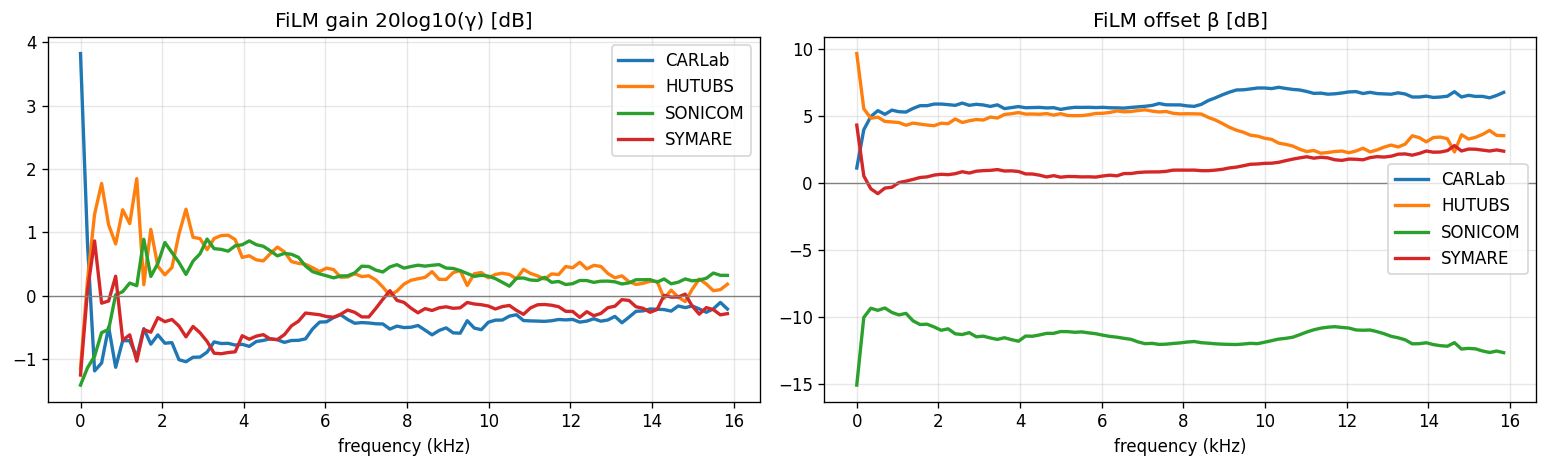

  CARLab    |γ| 峰值  3.82 dB | β 带内均值(≥500Hz)  +6.15 dB | |β| 峰值  7.13 dB
  HUTUBS    |γ| 峰值  1.85 dB | β 带内均值(≥500Hz)  +4.08 dB | |β| 峰值  9.64 dB
  SONICOM   |γ| 峰值  1.41 dB | β 带内均值(≥500Hz) -11.44 dB | |β| 峰值 15.06 dB
  SYMARE    |γ| 峰值  1.26 dB | β 带内均值(≥500Hz)  +1.21 dB | |β| 峰值  4.31 dB
⚠️ β 的峰值常常落在 DC bin —— 报数时把 DC 和带内分开说。


In [ ]:
# ==========================================================================
# Cell 6 — 载入 checkpoint（只做评估时从这里开始,跳过 Cell 5）
# ==========================================================================
ckpt = torch.load(best_path, map_location=device, weights_only=False)
n_ds_ck, n_bins_ck = ckpt['model_state_dict']['decoder.film.beta'].shape
assert (n_bins_ck, n_ds_ck) == (config['num_bins'], config['num_datasets']), \
    f"存档 {n_ds_ck} 库 / {n_bins_ck} bin,当前 {config['num_datasets']} / {config['num_bins']}"
model.load_state_dict(ckpt['model_state_dict']); model.eval()
history = ckpt.get('history', {})
SPLIT = ckpt['split']
baselines = ckpt.get('baselines', {})

# The checkpoint split is the only split permitted for evaluation.  Rebuild the
# datasets/loaders *after* loading it: changing SPLIT alone would leave the old
# pre-built loaders in memory and silently evaluate a mismatched subject list.
assert set(TAGS) == set(SPLIT), 'checkpoint split does not match the four loaded datasets'
tr_parts, va_parts, te_parts = [], [], []
for d in DATASETS:
    s = SPLIT[d['tag']]
    tr_parts.append(MonauralHRTFDataset(d, s['train'], MIRROR))
    va_parts.append(MonauralHRTFDataset(d, s['val'], MIRROR))
    te_parts.append(MonauralHRTFDataset(d, s['test'], MIRROR))
train_dataset, val_dataset, test_dataset = (ConcatDataset(x) for x in (tr_parts, va_parts, te_parts))
val_loader  = DataLoader(val_dataset,  batch_size=config['batch_size'], shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=config['batch_size'], shuffle=False)

FFM26_CHECKPOINT_LOADED = True
FFM26_LOADED_WEIGHT_FINGERPRINT = (
    float(sum(p.detach().double().sum() for p in model.parameters())),
    float(sum(p.detach().double().square().sum() for p in model.parameters())))
FFM26_CHECKPOINT_META = dict(epoch=ckpt['epoch'], val_rmse=ckpt['val_rmse'],
                            split=SPLIT, path=best_path)
TEST_PREFLIGHT_PASSED = False
print(f"载入 {os.path.basename(best_path)} | epoch {ckpt['epoch']+1} | "
      f"val RMSE {ckpt['val_rmse']:.4f} dB")
for d in DATASETS:
    s = SPLIT[d['tag']]
    print(f"  {d['tag']:<9} train {len(s['train']):>4} / val {len(s['val']):>3} / test {len(s['test']):>3} 人")
del ckpt
if torch.cuda.is_available(): torch.cuda.empty_cache()

# ★ 四库学到的「测量染色」—— 应当像 EQ:平缓、宽包络。出现 notch 结构就说明
#   FiLM 在吸收本该留给 latent 的人群解剖差异,那是 Craig 否定过的方向。
import matplotlib.pyplot as plt
with torch.no_grad():
    lg = (model.decoder.film.log_gamma - model.decoder.film.log_gamma.mean(0, keepdim=True)).cpu().numpy()
    bt = (model.decoder.film.beta - model.decoder.film.beta.mean(0, keepdim=True)).cpu().numpy()
fig, ax = plt.subplots(1, 2, figsize=(13, 4), dpi=120)
for k, t in enumerate(TAGS):
    ax[0].plot(freqs/1000, 20*np.log10(np.exp(lg[k])), lw=2, label=t)
    ax[1].plot(freqs/1000, bt[k], lw=2, label=t)
ax[0].set_title('FiLM gain 20log10(γ) [dB]'); ax[1].set_title('FiLM offset β [dB]')
for a in ax: a.set_xlabel('frequency (kHz)'); a.axhline(0, color='gray', lw=.8); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
for k, t in enumerate(TAGS):
    print(f'  {t:<9} |γ| 峰值 {np.abs(20*np.log10(np.exp(lg[k]))).max():5.2f} dB'
          f' | β 带内均值(≥500Hz) {bt[k][3:].mean():+6.2f} dB'
          f' | |β| 峰值 {np.abs(bt[k]).max():5.2f} dB')
print('⚠️ β 的峰值常常落在 DC bin —— 报数时把 DC 和带内分开说。')

In [ ]:
import torch, numpy as np, os, json
# 假设 model / MIRROR / DATASETS 已从 FFM_2_6 的 Cell 0–4 就位，且已 load FFM26_best
SYM = [d for d in DATASETS if d['tag']=='SYMARE'][0]
ids = sorted(json.load(open(split_path))['SYMARE']['train'])[:24]
Z, side = [], []
with torch.no_grad():
    for sid in ids:
        for s,sfx in (('left',SYM['suffix'][0]), ('right',SYM['suffix'][1])):
            p = os.path.join(SYM[s], f'{sid}{sfx}')
            if not os.path.exists(p): continue
            x = np.load(p).astype(np.float32)[:N_BINS]
            if s=='right': x = x[:, MIRROR]
            xt = torch.from_numpy(x)[None].to(device)
            Z.append(model(xt, torch.tensor([3], device=device))[1][0].float().cpu().numpy().ravel())
            side.append(s=='right')
Z = np.stack(Z); side = np.array(side)
v = Z[side].mean(0) - Z[~side].mean(0); v /= np.linalg.norm(v)
frac = 1 - (Z - np.outer(Z@v, v)).var() / Z.var()
print(f'side 方向占 latent 方差: {frac:.1%}   (v2.3 是 1.4%；>50% 说明镜像坏了)')

side 方向占 latent 方差: 4.0%   (v2.3 是 1.4%；>50% 说明镜像坏了)


/tmp/ipykernel_4217/2369696995.py:15: UserWarning: Glyph 34394 (\N{CJK UNIFIED IDEOGRAPH-865A}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_4217/2369696995.py:15: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_4217/2369696995.py:15: UserWarning: Glyph 21508 (\N{CJK UNIFIED IDEOGRAPH-5404}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_4217/2369696995.py:15: UserWarning: Glyph 24211 (\N{CJK UNIFIED IDEOGRAPH-5E93}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_4217/2369696995.py:15: UserWarning: Glyph 22522 (\N{CJK UNIFIED IDEOGRAPH-57FA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 34394 (\N{CJK UNIFIED IDEOGRAPH-865A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_fi

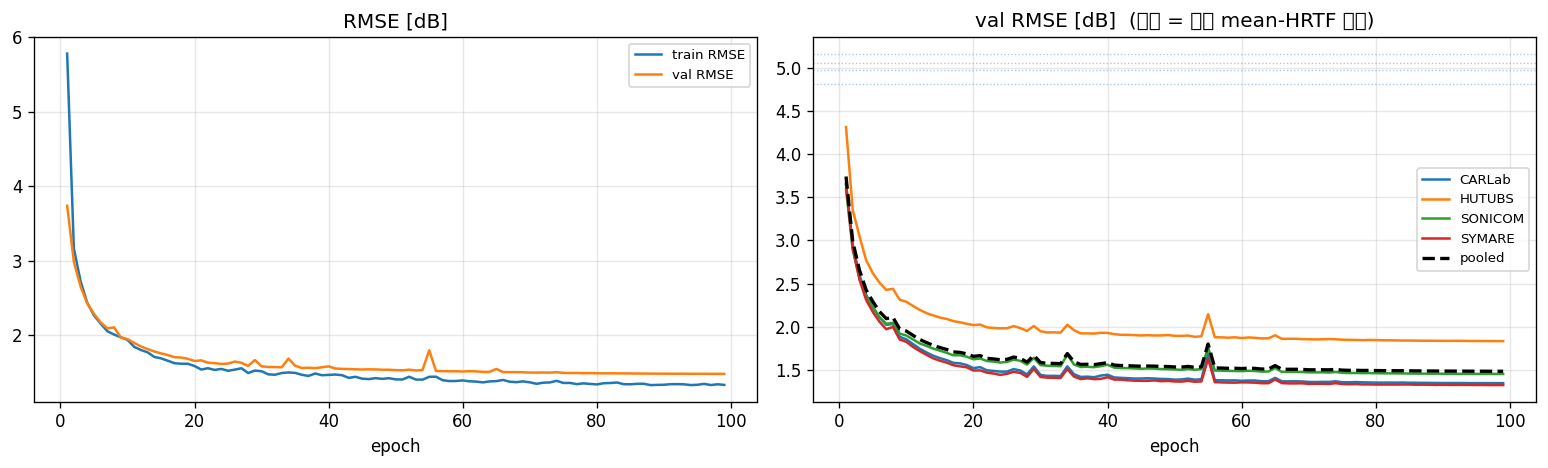

最好 pooled val 1.4855 dB @ epoch 99
★ v2.3 的 1.504 不是这条曲线的对照 —— 四库模型 + FiLM 多一行 = 不同的模型。


In [ ]:
# ==========================================================================
# Cell 7 — 训练曲线（含分库）
# ==========================================================================
ep = np.arange(1, len(history['val_rmse']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4), dpi=120)
ax[0].plot(ep, history['train_rmse'], lw=1.5, label='train RMSE')
ax[0].plot(ep, history['val_rmse'], lw=1.5, label='val RMSE')
ax[0].set_title('RMSE [dB]'); ax[0].legend(fontsize=8)
for k, t in enumerate(TAGS):
    ax[1].plot(ep, [h[t] for h in history['per_dataset']], lw=1.5, label=t)
    if t in baselines: ax[1].axhline(baselines[t], ls=':', lw=.8, alpha=.4)
ax[1].plot(ep, history['val_rmse'], 'k--', lw=2, label='pooled')
ax[1].set_title('val RMSE [dB]  (虚线 = 各库 mean-HRTF 基线)'); ax[1].legend(fontsize=8)
for a in ax: a.set_xlabel('epoch'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"最好 pooled val {min(history['val_rmse']):.4f} dB @ epoch "
      f"{int(np.argmin(history['val_rmse']))+1}")
print('★ v2.3 的 1.504 不是这条曲线的对照 —— 四库模型 + FiLM 多一行 = 不同的模型。')

In [ ]:
def side_frac_of(d, ids, nmax=30):
    Z, sd = [], []
    with torch.no_grad():
        did = torch.tensor([d['id']], device=device)
        for sid in sorted(ids)[:nmax]:
            for s, sfx in (('left', d['suffix'][0]), ('right', d['suffix'][1])):
                p = os.path.join(d[s], f'{sid}{sfx}')
                if not os.path.exists(p): continue
                x = np.load(p).astype(np.float32)[:N_BINS]
                if s == 'right': x = x[:, MIRROR]
                xt = torch.from_numpy(x)[None].to(device)
                Z.append(model(xt, did)[1][0].float().cpu().numpy().ravel()); sd.append(s=='right')
    Z = np.stack(Z); sd = np.array(sd)
    v = Z[sd].mean(0) - Z[~sd].mean(0); v /= np.linalg.norm(v)
    return 1 - (Z - np.outer(Z@v, v)).var() / Z.var(), Z.var()

print(f"{'库':<9}{'side 方差占比':>14}{'latent 总方差':>14}")
for d in DATASETS:
    f_, tv = side_frac_of(d, SPLIT[d['tag']]['train'])
    print(f"{d['tag']:<9}{f_:>13.1%}{tv:>14.4f}")

库             side 方差占比    latent 总方差
CARLab            0.8%     2953.0508
HUTUBS            2.5%     3040.5144
SONICOM           0.6%     2515.4087
SYMARE            1.8%     2895.3379


In [ ]:
SYM_ds = next(d for d in DATASETS if d['tag'] == 'SYMARE')

for part in ('train', 'val', 'test'):
    ids = SPLIT['SYMARE'][part]
    f_, tv = side_frac_of(SYM_ds, ids, nmax=99)
    print(f'{part:<6} n={len(ids):>2}  side {f_:>6.1%}  var {tv:.1f}')

train  n=37  side   2.0%  var 2905.8
val    n= 9  side   7.6%  var 2835.3
test   n=15  side   1.0%  var 2964.2


In [ ]:
# ==========================================================================
# Cell 8 — ★ TEST scalar preflight (run before heatmap/download Cell 9)
#
# This creates NO figures and downloads nothing. It first proves that the LIVE
# model reproduces the checkpoint validation RMSE; only then does it read test.
# ==========================================================================
RUN_TEST_PREFLIGHT = False  # set True only when you want to read the held-out test scalar

if not RUN_TEST_PREFLIGHT:
    print('RUN_TEST_PREFLIGHT = False. Set True to print scalar RMSE only; no maps/downloads occur.')
else:
    assert globals().get('FFM26_CHECKPOINT_LOADED', False), 'Run Cell 6 successfully first.'
    assert not model.training, 'model must be in eval mode'
    now_fingerprint = (
        float(sum(p.detach().double().sum() for p in model.parameters())),
        float(sum(p.detach().double().square().sum() for p in model.parameters())))
    assert now_fingerprint == FFM26_LOADED_WEIGHT_FINGERPRINT, (
        'Model parameters changed after checkpoint loading (for example, FiLM was re-initialised). '
        'Restart from Cell 0 and load Cell 6 again.')

    live_val_rmse, live_val_mae, live_val_per = evaluate(val_loader)
    expected_val_rmse = FFM26_CHECKPOINT_META['val_rmse']
    tolerance = 0.03
    print(f'LIVE validation RMSE {live_val_rmse:.4f} dB | checkpoint {expected_val_rmse:.4f} dB')
    assert abs(live_val_rmse - expected_val_rmse) <= tolerance, (
        f'Validation replay failed by {abs(live_val_rmse - expected_val_rmse):.4f} dB. '
        'Do NOT make heatmaps/downloads: checkpoint, FiLM, split, or data state is wrong.')

    test_rmse, test_mae, test_per = evaluate(test_loader)
    print(f'\nTEST scalar preflight: pooled RMSE {test_rmse:.4f} dB | MAE {test_mae:.4f} dB')
    print(f"{'database':<9}{'test RMSE':>12}{'val RMSE':>12}")
    for t in TAGS:
        print(f'{t:<9}{test_per[t]:>12.4f}{live_val_per[t]:>12.4f}')
    TEST_PREFLIGHT_PASSED = True
    print('\nPreflight passed. Review this scalar result before setting RUN_HEATMAPS=True in Cell 9.')

In [ ]:
# ==========================================================================
# Cell 9 — locked scalar evaluation + per-ear HEALPix heatmaps (FFM26)
#
# Run this only after Cell 6 has loaded FFM26_best.pth. For SPLIT_NAME='test',
# first run the scalar preflight in Cell 8 successfully, review it, then set
# RUN_HEATMAPS=True below. The scalar metrics are written before any map is drawn.
# ==========================================================================

RUN_HEATMAPS      = False  # final switch: maps and the selected split are not touched while False
SPLIT_NAME        = 'test' # 'test' (final only) or 'val' (safe diagnostic)
BIN_GROUP         = 5      # 93 bins -> 19 frequency-band maps
MAX_SUBJECTS_PER_DB = None # None = every subject; set e.g. 4 only for a smoke test
ONLY_DB           = None   # e.g. {'SYMARE'}; None = all four databases
RESUME            = True   # preserve completed subject folders within the same output root
DPI               = 110
ZIP_PART_MB       = 180
OUT_ROOT          = '/content/bandmaps'
RUN_LABEL         = None   # e.g. '20260909_120000' to resume that exact output folder
COPY_ZIPS_TO_DRIVE = True

if not RUN_HEATMAPS:
    print('RUN_HEATMAPS = False. Set it to True only when the selected split is authorised.')
    print("For validation maps, set SPLIT_NAME='val'. For test maps, run and review Cell 8 first.")
else:
    assert SPLIT_NAME in {'test', 'val'}, "SPLIT_NAME must be 'test' or 'val'"
    if SPLIT_NAME == 'test':
        assert globals().get('TEST_PREFLIGHT_PASSED', False), (
            'TEST heatmaps require a successful Cell 8 scalar preflight in this runtime. '
            'Run Cell 8 with RUN_TEST_PREFLIGHT=True, review its RMSE, then run this cell.')

    import csv
    import json
    import math
    import shutil
    import time
    import zipfile
    from pathlib import Path

    import healpy as hp
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt

    # ---- Frequency bands and selected datasets ----
    NB, FS = config['num_bins'], config['sample_rate']
    DF = FS / 256.0
    FREQS = np.arange(NB) * DF
    EDGES = [(i * BIN_GROUP, min((i + 1) * BIN_GROUP, NB))
             for i in range(math.ceil(NB / BIN_GROUP))]
    F_LO = np.asarray([a * DF for a, _ in EDGES])
    F_HI = np.asarray([(b - 1) * DF for _, b in EDGES])
    BAND_MASK = FREQS >= config['band_lo_hz']
    BAND_TORCH = torch.as_tensor(BAND_MASK, dtype=torch.bool)
    NOTCH_MASK = (FREQS >= 6000) & (FREQS <= 12000)

    parts = {'test': te_parts, 'val': va_parts}[SPLIT_NAME]
    loader = {'test': test_loader, 'val': val_loader}[SPLIT_NAME]
    TAG_BY_ID = {d['id']: d['tag'] for d in DATASETS}
    stamp = time.strftime('%Y-%m-%d %H:%M:%S')
    run_id = RUN_LABEL or time.strftime('%Y%m%d_%H%M%S')
    root = Path(f'{OUT_ROOT}_{SPLIT_NAME}_FFM26_{run_id}')

    print(f'FFM26 heatmaps | split={SPLIT_NAME} | {NB} bins | {DF:.2f} Hz/bin | '
          f'{len(EDGES)} bands')
    for part in parts:
        print(f'  {TAG_BY_ID[part.dataset_id]:<9} {len(part.items)//2:>3} subjects / {len(part):>3} ears')

    # ---- Baseline for the selected split, calculated from that database's training ears ----
    # This deliberately does not reuse Cell 4's validation baseline when SPLIT_NAME='test'.
    def selected_split_baselines():
        result = {}
        for tag, train_part, target_part in zip(TAGS, tr_parts, parts):
            mean_x = None
            for i in range(len(train_part)):
                x = train_part[i][0].double()
                mean_x = x if mean_x is None else mean_x + x
            mean_x = mean_x / len(train_part)

            se, count = 0.0, 0
            for i in range(len(target_part)):
                e = target_part[i][0].double()[BAND_TORCH] - mean_x[BAND_TORCH]
                se += float((e * e).sum())
                count += e.numel()
            result[tag] = math.sqrt(se / count)
        return result

    # ---- Lock scalar results before viewing any map ----
    model.eval()
    assert not model.training, 'model must be in eval mode'
    n_bn = sum(isinstance(m, (torch.nn.BatchNorm1d, torch.nn.BatchNorm2d)) for m in model.modules())
    n_dp = sum(isinstance(m, torch.nn.Dropout) for m in model.modules())
    weight_signature = float(sum(p.detach().double().sum() for p in model.parameters()))

    t0 = time.time()
    rmse, mae, per_db = evaluate(loader)
    split_baselines = selected_split_baselines()
    print(f'Locked scalar evaluation completed in {time.time() - t0:.0f}s')

    root.mkdir(parents=True, exist_ok=True)
    lock_lines = [
        f'FFM26 {SPLIT_NAME.upper()} scalar evaluation — recorded before maps are rendered',
        f'timestamp: {stamp}',
        f'checkpoint: {Path(best_path).name}',
        f'weight signature: {weight_signature:.6f}',
        f'BatchNorm modules: {n_bn}; Dropout modules: {n_dp}',
        f'frequency scope: {config["band_lo_hz"]}–{config["band_hi_hz"]} Hz; '
        f'{int(BAND_MASK.sum())}/{NB} bins; HEALPix nside={config["nside"]}',
        '=' * 72,
        f'{"database":<10}{"subjects":>10}{"ears":>8}{"RMSE dB":>12}{"train-mean baseline dB":>25}',
    ]
    for part in parts:
        tag = TAG_BY_ID[part.dataset_id]
        lock_lines.append(f'{tag:<10}{len(part.items)//2:>10}{len(part):>8}'
                          f'{per_db[tag]:>12.4f}{split_baselines[tag]:>25.4f}')
    lock_lines += [
        f'{"pooled":<10}{"":>10}{sum(len(p) for p in parts):>8}{rmse:>12.4f}',
        f'{"MAE":<10}{"":>10}{"":>8}{mae:>12.4f}',
        '',
        'Metric: pooled RMSE over selected-loss-band frequency × direction × all ears.',
        'The per-database baseline is that database training-set mean spectrum, evaluated on this selected split.',
        '',
        'HUTUBS repeat-pair split audit:',
    ]

    def split_bucket(subject):
        canonical = subject.removeprefix('HU_')
        for bucket in ('train', 'val', 'test'):
            ids = SPLIT.get('HUTUBS', {}).get(bucket, [])
            if subject in ids or canonical in [x.removeprefix('HU_') for x in ids]:
                return bucket
        return 'not found'

    for a, b in (('HU_pp1', 'HU_pp96'), ('HU_pp22', 'HU_pp88')):
        wa, wb = split_bucket(a), split_bucket(b)
        verdict = 'same split — no cross-split leakage' if wa == wb else 'WARNING: cross-split pair'
        lock_lines.append(f'  {a:<8} {wa:<9} | {b:<8} {wb:<9} | {verdict}')

    locked_text = '\n'.join(lock_lines) + '\n'
    (root / '_LOCKED_metrics.txt').write_text(locked_text)
    print('\n' + locked_text)
    print('Scalar metrics are now locked. If map inspection motivates a model change, invalidate these numbers and rerun.')

    def band_average(x):
        return np.stack([x[a:b].mean(axis=0) for a, b in EDGES])

    def draw_band(gt, pred, band_index, tag, subject, ear, path):
        err = np.abs(gt - pred)
        vmin, vmax = float(min(gt.min(), pred.min())), float(max(gt.max(), pred.max()))
        fig = plt.figure(figsize=(16, 4.6), dpi=DPI)
        fig.suptitle(
            f'{tag} / {subject} / {ear} ear'
            f'{" (mirrored to left-ear frame)" if ear == "right" else ""}'
            f'   band {band_index:02d}: {F_LO[band_index]/1000:.2f}–{F_HI[band_index]/1000:.2f} kHz'
            f'   MAE {err.mean():.2f} dB; max {err.max():.2f} dB',
            fontsize=13, fontweight='bold', y=1.04)
        hp.mollview(gt, fig=fig.number, sub=(1, 3, 1), title='Ground truth',
                    min=vmin, max=vmax, cmap='viridis', unit='dB', format='%.1f')
        hp.mollview(pred, fig=fig.number, sub=(1, 3, 2), title='Prediction',
                    min=vmin, max=vmax, cmap='viridis', unit='dB', format='%.1f')
        hp.mollview(err, fig=fig.number, sub=(1, 3, 3), title='Absolute error',
                    cmap='hot', unit='dB', format='%.1f')
        fig.savefig(path, bbox_inches='tight', facecolor='white')
        plt.close(fig)

    def draw_frequency_error(gt, pred, tag, subject, ear, path):
        rms_by_frequency = np.sqrt(((gt - pred) ** 2).mean(axis=1))
        bias_by_frequency = (pred - gt).mean(axis=1)
        fig, ax = plt.subplots(figsize=(12, 4.4), dpi=DPI)
        ax.plot(FREQS / 1000, rms_by_frequency, lw=2.2, color='#c0392b', label='RMS error')
        ax.plot(FREQS / 1000, bias_by_frequency, lw=1.4, ls='--', color='#2471a3',
                label='mean bias (prediction − GT)')
        ax.axhline(0, color='black', lw=.6)
        ax.axvspan(6, 12, color='orange', alpha=.12, label='notch band (6–12 kHz)')
        for lo in F_LO:
            ax.axvline(lo / 1000, color='grey', lw=.4, alpha=.5)
        ax.set(xlabel='frequency (kHz)', ylabel='dB', xlim=(0, FREQS[-1] / 1000),
               title=f'{tag} / {subject} / {ear}: error versus frequency')
        ax.legend(fontsize=9)
        ax.grid(alpha=.3)
        fig.tight_layout()
        fig.savefig(path, facecolor='white')
        plt.close(fig)
        return rms_by_frequency

    def error_summary(gt, pred):
        error = pred - gt
        return {
            'rmse_band': float(np.sqrt((error[BAND_MASK] ** 2).mean())),
            'rmse_all': float(np.sqrt((error ** 2).mean())),
            'lsd': float(np.sqrt((error ** 2).mean(axis=0)).mean()),
            'mae': float(np.abs(error).mean()),
            'bias': float(error.mean()),
            'rmse_notch': float(np.sqrt((error[NOTCH_MASK] ** 2).mean())),
            'peak': float(np.abs(error).max()),
        }

    # ---- Render each ear, with restart support ----
    jobs = []
    for part in parts:
        tag = TAG_BY_ID[part.dataset_id]
        if ONLY_DB is not None and tag not in ONLY_DB:
            continue
        n_ears = len(part) if MAX_SUBJECTS_PER_DB is None else min(len(part), 2 * MAX_SUBJECTS_PER_DB)
        jobs.extend((part, tag, i) for i in range(n_ears))

    print(f'Rendering {len(jobs)} ears × {len(EDGES) + 1} PNGs …')
    rows, render_start, done = [], time.time(), 0
    with torch.no_grad():
        for part, tag, i in jobs:
            x, did, name = part[i]
            subject, ear = name.rsplit('_', 1)
            subject_dir = root / tag / name
            error_json = subject_dir / 'zz_errors.json'

            if RESUME and error_json.exists():
                rows.append(json.loads(error_json.read_text()))
                done += 1
                continue

            subject_dir.mkdir(parents=True, exist_ok=True)
            prediction, _ = model(x.unsqueeze(0).to(device), did.view(1).to(device))
            gt = x.numpy()
            pred = prediction[0].float().cpu().numpy()
            gt_band, pred_band = band_average(gt), band_average(pred)

            for b in range(len(EDGES)):
                filename = f'band_{b:02d}_{F_LO[b]/1000:05.2f}-{F_HI[b]/1000:05.2f}kHz.png'
                draw_band(gt_band[b], pred_band[b], b, tag, subject, ear, subject_dir / filename)
            rms_frequency = draw_frequency_error(gt, pred, tag, subject, ear,
                                                 subject_dir / 'zz_error_vs_frequency.png')

            row = error_summary(gt, pred)
            row.update(dataset=tag, subject=subject, ear=ear)
            rows.append(row)
            error_json.write_text(json.dumps(row, indent=2) + '\n')
            with open(subject_dir / 'zz_summary.txt', 'w') as handle:
                handle.write(f'{tag} / {subject} / {ear}\n' + '=' * 54 + '\n')
                for key in ('rmse_band', 'rmse_all', 'lsd', 'mae', 'bias', 'rmse_notch', 'peak'):
                    handle.write(f'{key:<12}{row[key]:>9.4f} dB\n')
                handle.write('\nper-band RMS error (dB)\n')
                for b, (lo, hi) in enumerate(EDGES):
                    handle.write(f'  band {b:02d}  {F_LO[b]/1000:5.2f}–{F_HI[b]/1000:5.2f} kHz'
                                 f'   {np.sqrt((rms_frequency[lo:hi] ** 2).mean()):.4f}\n')
            done += 1
            if done % 10 == 0:
                elapsed = time.time() - render_start
                remaining = elapsed / done * (len(jobs) - done)
                print(f'  {done}/{len(jobs)} ears | elapsed {elapsed/60:.1f} min | '
                      f'about {remaining/60:.1f} min remaining')

    end_signature = float(sum(p.detach().double().sum() for p in model.parameters()))
    assert end_signature == weight_signature, 'Model weights changed during inference'

    fields = ['dataset', 'subject', 'ear', 'rmse_band', 'rmse_all', 'lsd', 'mae', 'bias', 'rmse_notch', 'peak']
    rows.sort(key=lambda row: -row['rmse_band'])
    with open(root / '_ALL_subject_errors.csv', 'w', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows([{key: row[key] for key in fields} for row in rows])

    with open(root / '_README.txt', 'w') as handle:
        handle.write(
            f'FFM26 {SPLIT_NAME.upper()} per-ear error maps\n' + '=' * 64 + '\n\n'
            'rmse_band  Per-ear RMSE over selected-loss-band frequency × direction. The pooled metric\n'
            '           equals sqrt(mean_over_ears(rmse_band²)), not mean(rmse_band).\n'
            'rmse_all   Per-ear RMSE using all 93 bins.\n'
            'lsd        RMS over frequency, then arithmetic mean over direction.\n'
            'mae        Mean absolute error.\n'
            'bias       Mean(prediction − ground truth).\n'
            'rmse_notch RMSE only in 6–12 kHz.\n'
            'peak       Largest absolute error at one frequency-direction sample.\n\n'
            'Right ears are mirrored into the left-ear HEALPix frame before inference and plotting.\n'
        )

    per_ear = np.asarray([row['rmse_band'] for row in rows])
    print('\n' + '=' * 68)
    print(f'Ears rendered:                 {len(per_ear)}')
    print(f'Mean per-ear rmse_band:        {per_ear.mean():.4f} dB')
    print(f'Quadratic mean per-ear RMSE:   {np.sqrt((per_ear**2).mean()):.4f} dB '
          f'(locked pooled {rmse:.4f} dB)')
    print(f'Median / best / worst:         {np.median(per_ear):.4f} / {per_ear.min():.4f} / {per_ear.max():.4f} dB')
    print(f'Standard deviation:            {per_ear.std():.4f} dB')
    print('=' * 68)

    # ---- Package by database into browser-friendly pieces ----
    extras = [root / name for name in ('_LOCKED_metrics.txt', '_ALL_subject_errors.csv', '_README.txt')]
    def directory_size(path):
        return sum(file.stat().st_size for file in path.rglob('*') if file.is_file())

    def package_database(tag, directories):
        chunks, current, current_size = [], [], 0
        for directory in directories:
            size = directory_size(directory)
            if current and current_size + size > ZIP_PART_MB * 1e6:
                chunks.append(current)
                current, current_size = [], 0
            current.append(directory)
            current_size += size
        if current:
            chunks.append(current)

        archives = []
        for number, chunk in enumerate(chunks, 1):
            suffix = f'_part{number}of{len(chunks)}' if len(chunks) > 1 else ''
            archive = root.with_name(f'{root.name}_{tag}{suffix}.zip')
            with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED, compresslevel=1) as bundle:
                for extra in extras:
                    bundle.write(extra, extra.name)
                for directory in chunk:
                    for file in directory.rglob('*'):
                        if file.is_file():
                            bundle.write(file, file.relative_to(root))
            archives.append(archive)
            print(f'  {archive.name:<62}{archive.stat().st_size/1e6:>7.1f} MB | {len(chunk)} ears')
        return archives

    archives = []
    print('\nPackaging:')
    for tag in sorted({row['dataset'] for row in rows}):
        directories = sorted((root / tag).iterdir())
        archives.extend(package_database(tag, directories))

    if COPY_ZIPS_TO_DRIVE and os.path.isdir(config['save_dir']):
        for archive in archives:
            shutil.copy2(archive, config['save_dir'])
        print(f'\nArchives copied to {config["save_dir"]}')

    print('\nDownload one archive at a time in Colab:')
    print('from google.colab import files')
    for archive in archives:
        print(f'files.download({str(archive)!r})')


## 跑完之后

1. **重跑 `landmark2z`。** 这是这次重训最主要的收益:SYMARE 受试者现在有自己的
   latent,`symare61_to_carlab_RESOLVED.csv` 从流程里彻底移除,可用受试者从 52 变 61。
   `FFM_2_4` 需要改三处:数据源改成 SYMARE 的 `.npy`、`CARLAB_DID` 改成 `3`、
   映射表那一段删掉。

2. **旧结果全部作废,但要留着。** v2.3 + 映射得到的 dCor²ᵤ = 0.071 / CV-R² = 0.052 /
   端到端 4.208 dB,量的不是"几何 → 这个人的 latent"。`notes/landmark2z/` 里的
   `RESULTS_landmark2z.md` 要加一段说明,不要直接删——那是一次有记录的错误,
   属于 PROJECT_LOG 的更正登记。

3. **CARLab 的 mean-HRTF 基线应当仍是 5.053 dB**（Cell 4 会打印）。对不上就说明
   划分被动过了,停下来查。

4. **`FFM26_best.pth` 不覆盖 `FFM23_best.pth`。** 后者是 `landmark2z` 全部已发表
   数字的依据,必须保留到论文定稿。